# Lab 11: Attention


### Attention is a mechanism that allows a neural network to focus more on relevant information when making a prediction.

Encoder-decoder architecture with attention:
<img src="https://drive.google.com/thumbnail?id=1-QeHdZIeKTo_nAqfh7pRA_o4Nk8CAmP6&sz=w1000" width="700">

## Step 1 — Import libraries

In [1]:
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt
from google.colab import files

torch.manual_seed(42)

## Step 2 — Upload the dataset

In [4]:
from google.colab import files
ubload=files.upload()

Saving Lab_11_QnA_Dataset.csv to Lab_11_QnA_Dataset.csv


In [6]:
df = pd.read_csv("Lab_11_QnA_Dataset.csv")
print("Number of questions:", len(df))
print("Number of answer groups:", df["answer_id"].nunique())
display(df.head())


Number of questions: 168
Number of answer groups: 12


,question,answer_id,answer
0,Do you get hurt?,0,I don't have a body.
1,Do you have fingers?,0,I don't have a body.
2,Do you ever breathe,0,I don't have a body.
3,Do you masticate?,0,I don't have a body.
4,Can you throw up?,0,I don't have a body.


## Step 3 — Preprocessing

1. Lowercase each question and remove punctuation.
2. Give each word a number.
3. Make all questions the same length by adding zeros (**padding**).

In [7]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# 1. Lowercase
df["question"] = df["question"].str.lower()

# 2. Tokenization
tokenizer = Tokenizer()
tokenizer.fit_on_texts(df["question"])

# Convert words to numbers and add padding
X = pad_sequences(tokenizer.texts_to_sequences(df["question"]), padding="post")

# Answers
y = df["answer_id"].values

# Convert to PyTorch tensors
X = torch.tensor(X, dtype=torch.long)
y = torch.tensor(y, dtype=torch.long)

## Step 4 — Build an RNN with attention

- **Embedding** turns word numbers into vectors.
- **RNN** reads the words in sequence.
- **Attention** gives each word a weight.
- **Output** chooses one answer from the dataset.

In [11]:
class RNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.emb = nn.Embedding(len(tokenizer.word_index) + 1, 16) # convert to embeddings
        self.rnn = nn.RNN(16, 32) #(input size,output size)
        self.att = nn.Linear(32, 1)
        self.fc = nn.Linear(32, df["answer_id"].nunique())

    def forward(self, x):
        x, _ = self.rnn(self.emb(x))
        weights = torch.softmax(self.att(x), dim=1)
        return self.fc((x * weights).sum(1)), weights.squeeze(-1) # does not change

model = RNN()

## Step 5 — Train the model
The model learns which answer belongs to each question.

In [12]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

for epoch in range(50):
    loss = nn.functional.cross_entropy(model(X)[0], y) #calculate loss to reduce it
    loss.backward() #backpropagation to update parameters
    optimizer.step() #update parameters

print("Training finished!")

Training finished!


## Step 6 — See attention
The bar chart shows how much attention the model gives to each question word.

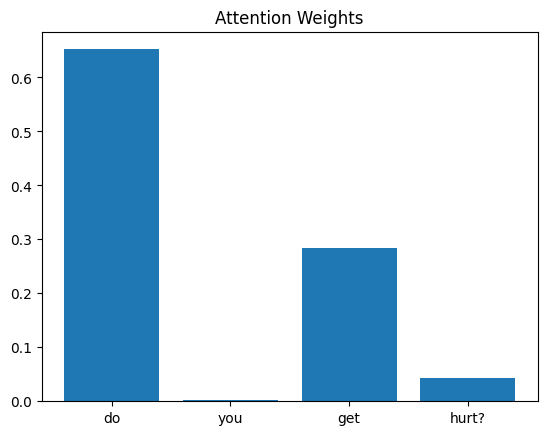

In [13]:
question = df["question"][0]
words = question.split()

with torch.no_grad():
    prediction, weights = model(X[:1])

plt.bar(words, weights[0, :len(words)].tolist())
plt.title("Attention Weights")
plt.show()

## Tasks:


Task 1 — Understand Attention Weights
Easy

Modify Step 6 to visualize the attention weights for three different questions from the dataset instead of only the first question.

Instructions:
- Select three questions from the dataset.
- Generate an attention bar chart for each question.
- Identify the word receiving the highest attention weight in each question.

Question: Do the words with the highest attention weights appear important for understanding the question? Explain your observations.

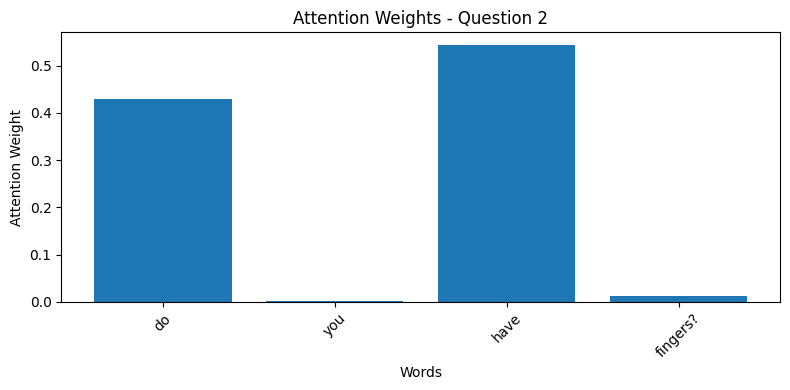

Question 2: do you have fingers?
Highest attention word: have
Attention weight: 0.5437
--------------------------------------------------


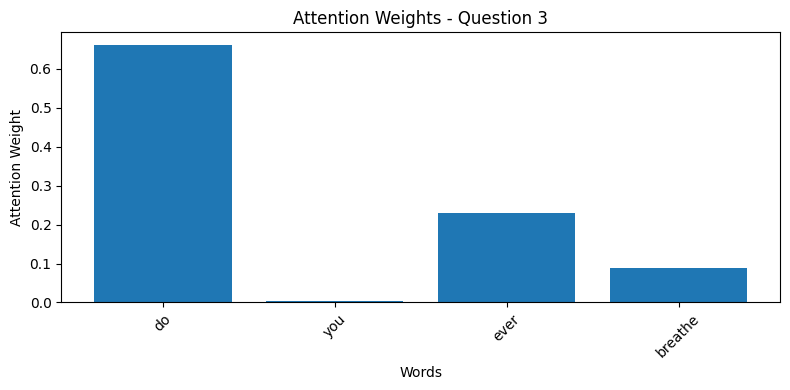

Question 3: do you ever breathe
Highest attention word: do
Attention weight: 0.6607
--------------------------------------------------


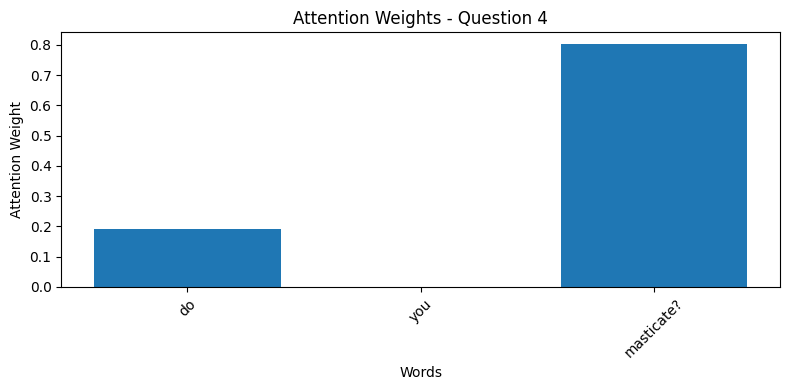

Question 4: do you masticate?
Highest attention word: masticate?
Attention weight: 0.8017
--------------------------------------------------


In [16]:
# Selecting three questions
for i in range(1,4):
    question = df["question"][i]
    words = question.split()

    with torch.no_grad():
        prediction, weights = model(X[i:i+1])

    attention_weights = weights[0, :len(words)].tolist()

    # Identify the word with the highest attention weight
    max_index = attention_weights.index(max(attention_weights))
    highest_word = words[max_index]

    # Plot attention weights
    plt.figure(figsize=(8, 4))
    plt.bar(words, attention_weights)
    plt.title(f"Attention Weights - Question {i+1}")
    plt.xlabel("Words")
    plt.ylabel("Attention Weight")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

    print(f"Question {i+1}: {question}")
    print(f"Highest attention word: {highest_word}")
    print(f"Attention weight: {attention_weights[max_index]:.4f}")
    print("-" * 50)

Task 2 — Compare Attention for Similar Questions
Medium

Select two questions from the dataset that have similar meanings but different wording.

Instructions:
- Pass both questions through the trained model.
- Visualize their attention weights.
- Compare the words receiving the highest attention weights.

Question: Does the model focus on similar or different words when processing questions with similar meanings? What does this suggest about how attention works?

In [17]:
df["question"].head(20)

,question
0,do you get hurt?
1,do you have fingers?
2,do you ever breathe
3,do you masticate?
4,can you throw up?
5,do you get tired?
6,can you crawl?
7,can you cry?
8,do you dream
9,do you ever pee?


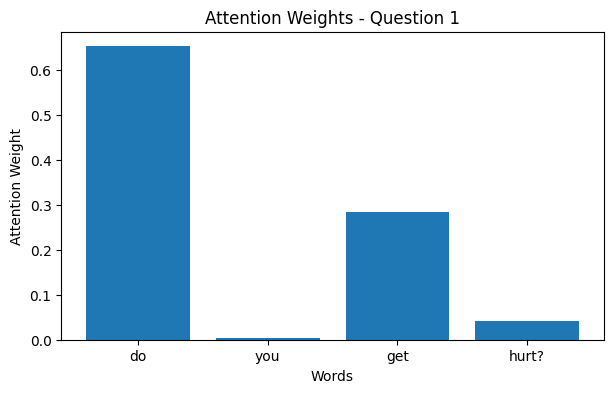

Question: do you get hurt?
Highest attention word: do
----------------------------------------


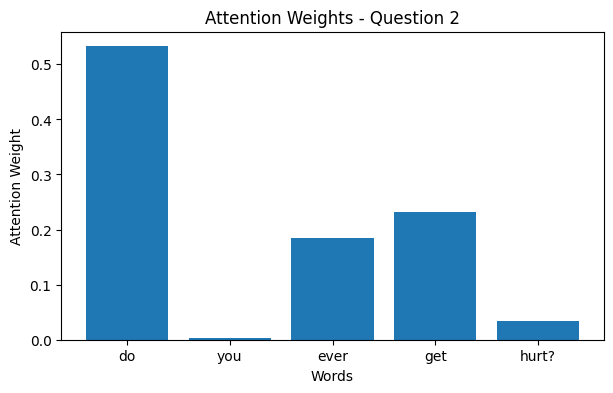

Question: do you ever get hurt?
Highest attention word: do
----------------------------------------


In [18]:
# Select two similar questions
idx1 = 0
idx2 = 10

questions = [df["question"][idx1], df["question"][idx2]]
indices = [idx1, idx2]

for i, question in enumerate(questions):

    words = question.split()

    with torch.no_grad():
        prediction, weights = model(X[indices[i]:indices[i]+1])

    attention_weights = weights[0, :len(words)].tolist()

    max_index = attention_weights.index(max(attention_weights))
    highest_word = words[max_index]

    plt.figure(figsize=(7, 4))
    plt.bar(words, attention_weights)
    plt.title(f"Attention Weights - Question {i+1}")
    plt.xlabel("Words")
    plt.ylabel("Attention Weight")
    plt.show()

    print(f"Question: {question}")
    print(f"Highest attention word: {highest_word}")
    print("-" * 40)

*** Both questions received similar attention weights,since "do" received the highest attention weight.On the other hand, the model gives some attention to the word "ever" in the second question,this suggests that attention helps the model focus on relevant words.